# 07 · Production Hybrid CICIDS2017 NIDS

Run this notebook top-to-bottom. It implements a leakage-safe CICIDS2017 NIDS with:

1. Drive persistence, raw audit, socket-column removal, train-only RF + MI feature selection, and cached arrays.
2. Engine A: Monday-benign FT-Transformer + TCN autoencoder for zero-day detection.
3. Engine B: unsupervised clustering of Engine A's Thursday/Friday anomalous traffic.
4. Engine C: isolated Tuesday-Friday specialist FT-Transformer + TCN classifiers with StratifiedShuffleSplit 70/30.

Existing notebooks are left intact. This notebook writes under `/content/drive/MyDrive/NIDS_CICIDS2017_Project/production_hybrid_nids/`.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
ROOT = Path('/content/drive/MyDrive/NIDS_CICIDS2017_Project')
RAW, EXTRACT = ROOT/'raw', ROOT/'extracted_generated_flows'
BASE = ROOT/'production_hybrid_nids'
CACHE, FEAT, MODELS, REP, CLUST = [BASE/p for p in ['cache','features','models','reports','clusters']]
for d in [RAW, EXTRACT, BASE, CACHE, FEAT, MODELS, REP, CLUST]:
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
SMOKE_TEST = False

import json, re, zipfile, joblib, gc
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.cluster import MiniBatchKMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import average_precision_score, classification_report, confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.utils.class_weight import compute_class_weight

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 80)
keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1 · Audit, Cleaning, and Zero-Leakage Feature Selection

Socket identifiers are dropped before any model-facing feature list is created. Splits happen before medians, scaling, RF/MI ranking, clustering, or modeling.

In [2]:
DAYS = ['Monday','Tuesday','Wednesday','Thursday','Friday']
EXPECTED_DATE = {'Monday':'2017-07-03','Tuesday':'2017-07-04','Wednesday':'2017-07-05','Thursday':'2017-07-06','Friday':'2017-07-07'}
SOCKET_META = ['Flow ID','Source IP','Src IP','Source Port','Src Port','Destination IP','Dst IP','Destination Port','Dst Port','Protocol','Timestamp','Label']

def clean_label(s):
    return s.astype(str).str.strip().str.replace(r'[^\x20-\x7E]+','-',regex=True)

def parse_ts(s):
    s = s.astype(str).str.strip()
    t = pd.to_datetime(s, format='%d/%m/%Y %H:%M', errors='coerce')
    miss = t.isna()
    if miss.any():
        t.loc[miss] = pd.to_datetime(s.loc[miss], dayfirst=True, errors='coerce', format='mixed')
    return t.where(t.dt.hour >= 8, t + pd.Timedelta(hours=12))

def day_from_name(p):
    return next(d for d in DAYS if d.lower() in p.name.lower())

def locate_csvs():
    csvs = sorted(EXTRACT.rglob('*.csv'))
    if len(csvs) != 8:
        zips = list(ROOT.rglob('GeneratedLabelledFlows*.zip'))
        assert zips, f'Put GeneratedLabelledFlows.zip under {RAW} or {ROOT}'
        with zipfile.ZipFile(zips[0]) as z:
            z.extractall(EXTRACT)
        csvs = sorted(EXTRACT.rglob('*.csv'))
    assert len(csvs) == 8, f'Expected 8 CSVs, found {len(csvs)}'
    return csvs

def build_clean_cache(force=False):
    if not force and all((CACHE/f'{d}.parquet').exists() for d in DAYS) and (FEAT/'raw_feature_candidates.json').exists():
        print('Clean cache already exists.')
        return
    audit, canonical = [], None
    day_frames = {d: [] for d in DAYS}
    for p in locate_csvs():
        day = day_from_name(p)
        df = pd.read_csv(p, low_memory=False, encoding_errors='replace')
        df.columns = [re.sub(r'\s+', ' ', str(c).strip()) for c in df.columns]
        n_raw = len(df)
        df = df.drop(columns=[c for c in df.columns if c == 'Fwd Header Length.1']).dropna(subset=['Label']).reset_index(drop=True)
        feats = [c for c in df.columns if c not in SOCKET_META]
        canonical = feats if canonical is None else canonical
        assert not (set(canonical) - set(feats)), f'Feature mismatch in {p.name}'
        X = df[canonical].apply(pd.to_numeric, errors='coerce')
        n_inf = int(np.isinf(X.to_numpy(dtype='float64')).sum())
        X = X.replace([np.inf, -np.inf], np.nan).astype('float32')
        out = X.copy()
        out['Timestamp'] = parse_ts(df['Timestamp'])
        out['Label'] = clean_label(df['Label'])
        out['day'] = day
        out['day_id'] = DAYS.index(day)
        assert out['Timestamp'].notna().all()
        day_frames[day].append(out)
        dates = sorted(map(str, out['Timestamp'].dt.date.unique()))
        audit.append({'file':p.name,'day':day,'rows_raw':n_raw,'rows_clean':len(out),'blank_rows_dropped':n_raw-len(out),'labels':out.Label.nunique(),'inf_to_nan':n_inf,'nan_feature_cells':int(out[canonical].isna().sum().sum()),'dates':','.join(dates),'date_ok':dates==[EXPECTED_DATE[day]],'features_after_socket_drop':len(canonical)})
    
    # Concatenate frames per day before writing to prevent overwrite bugs
    for day in DAYS:
        combined = pd.concat(day_frames[day], ignore_index=True)
        combined = combined.sort_values('Timestamp').reset_index(drop=True)
        combined.to_parquet(CACHE/f'{day}.parquet', index=False)
        print(f'Wrote {day}.parquet with {len(combined):,} rows.')

    pd.DataFrame(audit).sort_values('day').to_csv(REP/'cleaning_audit.csv', index=False)
    (FEAT/'raw_feature_candidates.json').write_text(json.dumps(canonical, indent=2))
    display(pd.DataFrame(audit).sort_values('day'))

build_clean_cache(False)
raw_features = json.loads((FEAT/'raw_feature_candidates.json').read_text())
def load_day(day): return pd.read_parquet(CACHE/f'{day}.parquet')
display(pd.concat([load_day(d).Label.value_counts().rename(d) for d in DAYS], axis=1).fillna(0).astype(int))
print('Behavior features after socket drop:', len(raw_features))
print('Excluded socket/meta fields:', SOCKET_META)



Clean cache already exists.


,Monday,Tuesday,Wednesday,Thursday,Friday
Label,,,,,
BENIGN,529918,432074,440031,168186,189067
FTP-Patator,0,7938,0,0,0
SSH-Patator,0,5897,0,0,0
DoS Hulk,0,0,231073,0,0
DoS GoldenEye,0,0,10293,0,0
DoS slowloris,0,0,5796,0,0
DoS Slowhttptest,0,0,5499,0,0
Heartbleed,0,0,11,0,0
Web Attack - Brute Force,0,0,0,1507,0


Behavior features after socket drop: 76
Excluded socket/meta fields: ['Flow ID', 'Source IP', 'Src IP', 'Source Port', 'Src Port', 'Destination IP', 'Dst IP', 'Destination Port', 'Dst Port', 'Protocol', 'Timestamp', 'Label']


In [3]:
TOP_K_FEATURES = 32
FS_TRAIN_DAYS = ['Monday','Tuesday','Wednesday']
FS_HELDOUT_DAYS = ['Thursday','Friday']

def slog(a):
    return (np.sign(a) * np.log1p(np.abs(a))).astype('float32')

ready = all((FEAT/p).exists() for p in ['selected_features.json','scaler.joblib','train_medians.joblib']) and all((CACHE/f'X_{d}.npy').exists() for d in DAYS)
if ready:
    selected = json.loads((FEAT/'selected_features.json').read_text())['features']
    scaler = joblib.load(FEAT/'scaler.joblib')
    print('Using persisted feature pipeline:', len(selected), 'features')
else:
    tr = pd.concat([load_day(d) for d in FS_TRAIN_DAYS], ignore_index=True)
    tr = tr[~tr.duplicated(subset=raw_features + ['Label'])].reset_index(drop=True)
    med = tr[raw_features].median()
    imp = tr[raw_features].fillna(med)
    constant = imp.nunique()[lambda s: s <= 1].index.tolist()
    rem = [c for c in raw_features if c not in constant]
    corr = imp[rem].sample(min(500_000, len(imp)), random_state=SEED).corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
    correlated = [c for c in upper.columns if (upper[c] > 0.95).any()]
    candidates = [c for c in rem if c not in correlated]
    y = (tr.Label != 'BENIGN').astype('int8').to_numpy()
    rng = np.random.default_rng(SEED)
    def cap(y, n):
        return np.sort(np.concatenate([rng.choice(np.where(y == c)[0], min(n, int((y == c).sum())), replace=False) for c in np.unique(y)]))
    X = imp[candidates].to_numpy('float32')
    irf, imi = cap(y, 80_000), cap(y, 15_000)
    rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=2, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED).fit(X[irf], y[irf])
    mi = mutual_info_classif(X[imi], y[imi], random_state=SEED)
    rank = pd.DataFrame({'feature':candidates, 'rf_importance':rf.feature_importances_, 'mutual_info':mi})
    rank['combined_rank'] = (rank.rf_importance.rank(ascending=False) + rank.mutual_info.rank(ascending=False)) / 2
    rank = rank.sort_values(['combined_rank','rf_importance'], ascending=[True,False]).reset_index(drop=True)
    selected = rank.feature.head(min(TOP_K_FEATURES, len(rank))).tolist()
    rank.to_csv(FEAT/'feature_ranking.csv', index=False)
    (FEAT/'selected_features.json').write_text(json.dumps({'k':len(selected),'features':selected,'fit_days':FS_TRAIN_DAYS,'held_out_days':FS_HELDOUT_DAYS,'socket_meta_excluded':SOCKET_META,'constant_dropped':constant,'correlated_dropped':correlated}, indent=2))
    joblib.dump({'medians':med[selected], 'all_medians':med}, FEAT/'train_medians.joblib')
    joblib.dump(rf, FEAT/'rf_feature_selector.joblib')
    scaler = StandardScaler().fit(slog(tr[selected].fillna(med[selected]).to_numpy('float32')))
    joblib.dump(scaler, FEAT/'scaler.joblib')
    for day in DAYS:
        df = load_day(day)
        Xd = df[selected].fillna(med[selected]).to_numpy('float32')
        Xd = np.clip(scaler.transform(slog(Xd)), -5, 5).astype('float32')
        np.save(CACHE/f'X_{day}.npy', Xd)
        df[['Timestamp','Label','day','day_id']].to_parquet(CACHE/f'y_{day}.parquet', index=False)
        print('saved', day, Xd.shape)
print('Selected features:', selected)

Using persisted feature pipeline: 32 features
Selected features: ['Packet Length Variance', 'Bwd Packet Length Max', 'Packet Length Mean', 'Fwd IAT Mean', 'Init_Win_bytes_backward', 'Flow IAT Max', 'Init_Win_bytes_forward', 'Flow Packets/s', 'Flow IAT Mean', 'Fwd IAT Std', 'Flow IAT Std', 'Fwd Packet Length Max', 'Flow Duration', 'Bwd Packets/s', 'Fwd Header Length', 'Bwd Header Length', 'Total Length of Fwd Packets', 'Min Packet Length', 'Flow Bytes/s', 'Total Fwd Packets', 'Bwd Packet Length Min', 'Fwd Packet Length Mean', 'Active Min', 'Active Mean', 'Active Max', 'Bwd IAT Total', 'Bwd IAT Max', 'Fwd IAT Min', 'Fwd Packet Length Min', 'Bwd IAT Mean', 'Bwd IAT Std', 'FIN Flag Count']


## Shared FT-Transformer + TCN Blocks

`TimeDistributed(ft_encoder)` bridges tabular flow tokens into a temporal tensor: `(batch, lookback, features)` → `(batch, lookback, embedding)`.

In [4]:
class FeatureTokenizer(layers.Layer):
    def __init__(self, n_features, d_token, **kw):
        super().__init__(**kw); self.n_features=int(n_features); self.d_token=int(d_token)
    def build(self, shape):
        self.w=self.add_weight(shape=(self.n_features,self.d_token), initializer='glorot_uniform', name='feature_weight')
        self.b=self.add_weight(shape=(self.n_features,self.d_token), initializer='zeros', name='feature_bias')
        self.cls=self.add_weight(shape=(1,1,self.d_token), initializer='glorot_uniform', name='cls_token')
    def call(self, x):
        tok=x[...,None]*self.w+self.b
        return tf.concat([tf.tile(self.cls,[tf.shape(x)[0],1,1]), tok], axis=1)
    def get_config(self):
        return {**super().get_config(), 'n_features':self.n_features, 'd_token':self.d_token}

class FTBlock(layers.Layer):
    def __init__(self, d_token=48, n_heads=4, ff_mult=2, dropout=0.1, **kw):
        super().__init__(**kw); self.d_token=d_token; self.n_heads=n_heads; self.ff_mult=ff_mult; self.dropout=dropout
        self.n1=layers.LayerNormalization(epsilon=1e-6); self.n2=layers.LayerNormalization(epsilon=1e-6)
        self.att=layers.MultiHeadAttention(num_heads=n_heads, key_dim=d_token//n_heads, dropout=dropout)
        self.f1=layers.Dense(ff_mult*d_token, activation='gelu'); self.f2=layers.Dense(d_token); self.dr=layers.Dropout(dropout)
    def call(self, x, training=None):
        h=self.n1(x); x=x+self.dr(self.att(h,h,training=training), training=training)
        h=self.n2(x); return x+self.dr(self.f2(self.dr(self.f1(h), training=training)), training=training)
    def get_config(self):
        return {**super().get_config(), 'd_token':self.d_token, 'n_heads':self.n_heads, 'ff_mult':self.ff_mult, 'dropout':self.dropout}

def build_ft_encoder(n_features, d_token=48, n_heads=4, n_blocks=2, dropout=0.1, name='ft_encoder'):
    inp=keras.Input((n_features,), name='flow_features')
    x=FeatureTokenizer(n_features,d_token)(inp)
    for i in range(n_blocks):
        x=FTBlock(d_token,n_heads,2,dropout,name=f'ft_block_{i+1}')(x)
    return keras.Model(inp, layers.LayerNormalization(epsilon=1e-6)(x[:,0,:]), name=name)

def tcn_stack(x, filters=96, kernel_size=3, dilations=(1,2,4,8), dropout=0.1):
    for d in dilations:
        res=x
        h=layers.Conv1D(filters,kernel_size,padding='causal',dilation_rate=d)(x)
        h=layers.LayerNormalization(epsilon=1e-6)(h); h=layers.Activation('relu')(h); h=layers.SpatialDropout1D(dropout)(h)
        h=layers.Conv1D(filters,kernel_size,padding='causal',dilation_rate=d)(h)
        h=layers.LayerNormalization(epsilon=1e-6)(h)
        if res.shape[-1] != filters:
            res=layers.Conv1D(filters,1,padding='same')(res)
        x=layers.Activation('relu')(layers.Add()([h,res]))
    return x

def make_windows(X, labels=None, lookback=10, stride=1):
    ends=np.arange(lookback-1, len(X), stride, dtype=np.int64)
    win=np.stack([X[e-lookback+1:e+1] for e in ends]).astype('float32')
    return (win, ends) if labels is None else (win, labels[ends], ends)

CUSTOM_OBJECTS={'FeatureTokenizer':FeatureTokenizer,'FTBlock':FTBlock}

## 2 · Engine A: Monday-Benign Zero-Day Autoencoder

The autoencoder trains only on benign Monday windows. The threshold is Monday reconstruction MSE p99, then frozen for Thursday/Friday.

In [5]:
LOOKBACK_AE=10; AE_BATCH=512; AE_EPOCHS=4 if not SMOKE_TEST else 2; AE_PATIENCE=5
selected=json.loads((FEAT/'selected_features.json').read_text())['features']; F=len(selected)

def build_zero_day_autoencoder(n_features, lookback):
    inp=keras.Input((lookback,n_features), name='window_features')
    ft=build_ft_encoder(n_features, 48, 4, 2, 0.1, 'ae_ft_encoder')
    z=layers.TimeDistributed(ft, name='encode_each_flow')(inp)
    z=tcn_stack(z, 96, 3, (1,2,4,8), 0.1)
    z=layers.Conv1D(64, 1, activation='relu', name='temporal_bottleneck')(z)
    out=layers.TimeDistributed(layers.Dense(n_features), name='reconstruct_each_flow')(z)
    return keras.Model(inp, out, name='ft_transformer_tcn_autoencoder')

def train_or_load_ae():
    mdir=MODELS/'zero_day_autoencoder'; mdir.mkdir(parents=True, exist_ok=True)
    final=mdir/'zero_day_autoencoder.keras'; thp=mdir/'threshold.json'
    if final.exists() and thp.exists():
        return keras.models.load_model(final, custom_objects=CUSTOM_OBJECTS), json.loads(thp.read_text())['threshold_mse_p99']
    X=np.load(CACHE/'X_Monday.npy')
    y=pd.read_parquet(CACHE/'y_Monday.parquet')
    Xb=X[y.Label.to_numpy() == 'BENIGN']
    Xw,_=make_windows(Xb, lookback=LOOKBACK_AE)
    if SMOKE_TEST: Xw=Xw[:5000]
    rng=np.random.default_rng(SEED); perm=rng.permutation(len(Xw)); vn=max(1,int(.1*len(perm)))
    va,tr=perm[:vn],perm[vn:]
    model=build_zero_day_autoencoder(F, LOOKBACK_AE)
    model.compile(keras.optimizers.AdamW(5e-4, weight_decay=1e-4, clipnorm=1.0), loss='mse')
    cb=[keras.callbacks.ModelCheckpoint(str(mdir/'best_zero_day_autoencoder.keras'), monitor='val_loss', mode='min', save_best_only=True, verbose=1),
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=AE_PATIENCE, restore_best_weights=True)]
    hist=model.fit(Xw[tr], Xw[tr], validation_data=(Xw[va],Xw[va]), epochs=AE_EPOCHS, batch_size=AE_BATCH, callbacks=cb, verbose=1)
    mse=np.mean(np.square(model.predict(Xw,batch_size=2048,verbose=0)-Xw), axis=(1,2))
    thr=float(np.percentile(mse, 99))
    model.save(final); np.save(mdir/'monday_train_mse.npy', mse); pd.DataFrame(hist.history).to_csv(mdir/'training_history.csv', index=False)
    thp.write_text(json.dumps({'threshold_mse_p99':thr,'lookback':LOOKBACK_AE,'train_source':'Monday BENIGN only'}, indent=2))
    return model, thr

ae_model, ae_threshold = train_or_load_ae()
print('AE threshold:', ae_threshold)

Epoch 1/4
932/932 ━━━━━━━━━━━━━━━━━━━━ 0s 235ms/step - loss: 0.3506
Epoch 1: val_loss improved from None to 0.02277, saving model to /content/drive/MyDrive/NIDS_CICIDS2017_Project/production_hybrid_nids/models/zero_day_autoencoder/best_zero_day_autoencoder.keras

Epoch 1: finished saving model to /content/drive/MyDrive/NIDS_CICIDS2017_Project/production_hybrid_nids/models/zero_day_autoencoder/best_zero_day_autoencoder.keras
932/932 ━━━━━━━━━━━━━━━━━━━━ 416s 283ms/step - loss: 0.1478 - val_loss: 0.0228
Epoch 2/4
932/932 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - loss: 0.0257
Epoch 2: val_loss improved from 0.02277 to 0.00900, saving model to /content/drive/MyDrive/NIDS_CICIDS2017_Project/production_hybrid_nids/models/zero_day_autoencoder/best_zero_day_autoencoder.keras

Epoch 2: finished saving model to /content/drive/MyDrive/NIDS_CICIDS2017_Project/production_hybrid_nids/models/zero_day_autoencoder/best_zero_day_autoencoder.keras
932/932 ━━━━━━━━━━━━━━━━━━━━ 107s 114ms/step - loss: 0.0213 - 

In [6]:
def score_zero_day(day):
    X=np.load(CACHE/f'X_{day}.npy')
    meta=pd.read_parquet(CACHE/f'y_{day}.parquet')
    Xw,ends=make_windows(X, lookback=LOOKBACK_AE)
    pred=ae_model.predict(Xw, batch_size=2048, verbose=0)
    mse=np.mean(np.square(pred-Xw), axis=(1,2))
    out=meta.iloc[ends].reset_index(drop=True).copy()
    out['window_end_index']=ends
    out['reconstruction_mse']=mse
    out['is_unseen_attack']=mse > ae_threshold
    out.to_parquet(REP/f'zero_day_scores_{day}.parquet', index=False)
    return out

rows=[]
for day in ['Thursday','Friday']:
    s=score_zero_day(day)
    yb=(s.Label!='BENIGN').astype(int).to_numpy(); sc=s.reconstruction_mse.to_numpy(); fl=s.is_unseen_attack.to_numpy()
    rows.append({'day':day,'windows':len(s),'flagged_unseen':int(fl.sum()),'flag_rate':float(fl.mean()),'attack_recall_at_p99':float(fl[yb==1].mean()) if (yb==1).any() else np.nan,'benign_FPR':float(fl[yb==0].mean()) if (yb==0).any() else np.nan,'AP':float(average_precision_score(yb,sc)) if len(np.unique(yb))==2 else np.nan,'ROC_AUC':float(roc_auc_score(yb,sc)) if len(np.unique(yb))==2 else np.nan})
zd=pd.DataFrame(rows); zd.to_csv(REP/'zero_day_summary.csv', index=False); display(zd.round(4))

,day,windows,flagged_unseen,flag_rate,attack_recall_at_p99,benign_FPR,AP,ROC_AUC
0,Thursday,170357,1986,0.0117,0.0110,0.0117,0.0217,0.6867
1,Friday,191024,2154,0.0113,0.0193,0.0112,0.0157,0.6286


## 3 · Engine B: Unsupervised Clustering for Novel Attack Profiling

Only Engine A flagged vectors are clustered. Labels are displayed only for audit.

,Packet Length Variance,Bwd Packet Length Max,Packet Length Mean,Fwd IAT Mean,Init_Win_bytes_backward,Flow IAT Max,Init_Win_bytes_forward,Flow Packets/s,Flow IAT Mean,Fwd IAT Std,Flow IAT Std,Fwd Packet Length Max,Flow Duration,Bwd Packets/s,Fwd Header Length,Bwd Header Length,Total Length of Fwd Packets,Min Packet Length,Flow Bytes/s,Total Fwd Packets,Bwd Packet Length Min,Fwd Packet Length Mean,Active Min,Active Mean,Active Max,Bwd IAT Total,Bwd IAT Max,Fwd IAT Min,Fwd Packet Length Min,Bwd IAT Mean,Bwd IAT Std,FIN Flag Count,n_windows,dominant_label_audit_only,label_mix_audit_only
cluster,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
3,-0.290954,-0.072667,0.112420,-0.865959,-0.836777,-0.734279,-0.922025,0.707922,-0.723699,-0.786584,-0.614325,-0.037787,-0.745267,0.856670,-0.687593,-0.229125,-0.001575,1.109234,0.952014,-0.619125,1.057023,0.385593,-0.554969,-0.553122,-0.549208,-0.652038,-0.647892,-0.431099,1.176618,-0.629051,-0.705388,-0.208082,1185,BENIGN,{'BENIGN': 1185}
1,-1.316400,-1.086227,-1.271754,-1.091533,0.936479,-1.616527,0.440996,1.478097,-1.598785,-0.840948,-1.230613,-1.396013,-1.611184,1.639074,-1.092859,-0.397123,-1.475824,-0.349841,0.279018,-0.966415,-0.372767,-1.467150,-0.554969,-0.553122,-0.549208,-0.841367,-0.849738,-0.722450,-0.345574,-0.852685,-0.709426,-0.077109,710,BENIGN,"{'BENIGN': 695, 'Bot': 13, 'Web Attack - Brute..."
7,-1.158765,-1.660974,-1.080135,-0.734156,-0.903932,-1.810896,0.407804,1.761844,-1.797625,-0.790677,-1.284277,-0.939306,-1.796785,-0.974876,-0.479976,-2.491920,-0.903932,-0.275154,0.738006,-0.425427,-0.899705,-0.973938,-0.554969,-0.553122,-0.549208,-0.899824,-0.906958,-0.175505,-0.292777,-0.908463,-0.730591,-0.033589,692,BENIGN,{'BENIGN': 692}
2,0.815672,0.400371,0.644838,0.356564,0.928430,0.135877,1.185897,0.039319,-0.178016,0.580794,0.303856,1.068124,0.226282,0.148462,1.305909,1.082088,1.282102,-0.897601,0.586656,1.326948,-0.776805,0.803333,-0.554969,-0.553122,-0.549208,0.771277,0.754037,-0.007868,-0.865861,0.611191,0.722270,-0.206523,555,BENIGN,"{'BENIGN': 539, 'Bot': 16}"
6,0.882545,0.785442,0.731840,1.070274,0.969720,1.101885,1.061851,-0.966335,0.907381,1.233688,1.047930,1.124035,1.223297,-0.823204,1.715088,1.337494,1.389888,-0.871064,-0.446864,1.903472,-0.574452,0.725684,1.925983,2.106195,2.128882,1.457162,1.381680,0.176151,-0.816517,1.324344,1.462105,-0.231157,320,BENIGN,{'BENIGN': 320}
4,-1.407125,-1.427125,-1.550845,0.149655,0.498509,0.103089,0.544816,-0.784016,0.286537,-0.293831,-0.367627,-1.504474,0.047424,-0.634066,-0.912860,-0.982798,-1.488841,-0.552741,-1.447328,-0.555819,-0.659795,-1.635312,-0.541185,-0.540054,-0.536753,-0.672874,-0.674276,0.902181,-0.529840,-0.656202,-0.651570,0.018756,310,BENIGN,"{'BENIGN': 279, 'Web Attack - Brute Force': 18..."
5,-0.996841,-0.463613,-0.360848,1.363371,-0.246695,1.223956,-0.489539,-1.119921,1.338252,0.334624,1.238196,-0.286822,1.211809,-0.939786,0.046796,0.259666,0.054928,0.576036,-1.283555,0.130938,0.460629,-0.035331,1.737588,1.802840,1.711260,1.501019,1.556112,2.291109,0.718510,1.708708,0.322230,-0.208140,198,BENIGN,{'BENIGN': 198}
0,-0.693745,-0.947182,-0.488834,0.894043,-0.152257,0.877438,-0.057988,-0.850716,0.822972,0.999683,0.894068,-0.330418,0.855477,-0.885800,0.075755,-1.303993,0.088933,0.090562,-0.868821,1.064639,-0.052380,-0.258862,0.298732,0.561649,0.539581,-0.621285,-0.618214,0.022082,0.092922,-0.601970,-0.586929,0.010109,170,BENIGN,{'BENIGN': 170}


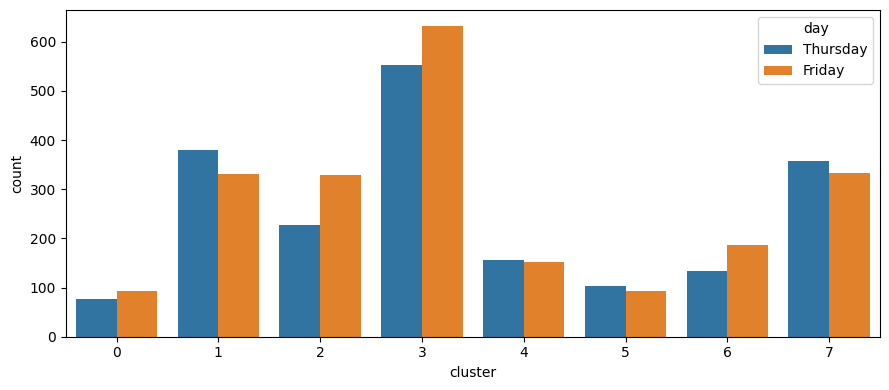

In [7]:
parts=[]
for day in ['Thursday','Friday']:
    scores=pd.read_parquet(REP/f'zero_day_scores_{day}.parquet')
    X=np.load(CACHE/f'X_{day}.npy')
    idx=scores.loc[scores.is_unseen_attack,'window_end_index'].to_numpy(dtype=int)
    if len(idx):
        parts.append((scores.loc[scores.is_unseen_attack].copy(), X[idx]))

if not parts:
    print('No anomalous windows flagged; clustering skipped.')
else:
    meta=pd.concat([p[0] for p in parts], ignore_index=True)
    X_anom=np.vstack([p[1] for p in parts]).astype('float32')
    path=CLUST/'kmeans_unseen_attacks.joblib'
    if path.exists():
        km=joblib.load(path); cid=km.predict(X_anom)
    else:
        k=min(8, max(2, len(X_anom)//50))
        km=MiniBatchKMeans(n_clusters=k, random_state=SEED, batch_size=4096, n_init='auto')
        cid=km.fit_predict(X_anom); joblib.dump(km, path)
    meta['cluster']=cid
    meta.to_parquet(CLUST/'unseen_attack_cluster_assignments.parquet', index=False)
    profile=pd.DataFrame(X_anom, columns=selected).groupby(cid).mean()
    profile.index.name='cluster'
    profile['n_windows']=meta.groupby('cluster').size()
    profile['dominant_label_audit_only']=meta.groupby('cluster').Label.agg(lambda s:s.value_counts().index[0])
    profile['label_mix_audit_only']=meta.groupby('cluster').Label.agg(lambda s:dict(s.value_counts().head(5)))
    profile.to_csv(CLUST/'cluster_feature_profiles.csv')
    display(profile.sort_values('n_windows', ascending=False))
    plt.figure(figsize=(9,4)); sns.countplot(data=meta,x='cluster',hue='day'); plt.tight_layout(); plt.savefig(CLUST/'cluster_sizes.png',dpi=140); plt.show()

## 4 · Engine C: Isolated Per-Day Specialist Classifiers

Each Tuesday-Friday model has its own stratified 70/30 split, train-fold-only feature selector/scaler, Keras checkpoint, final `.keras` model, classification report, confusion matrix, and ROC/PR curves.

In [8]:
LOOKBACK_CLS = 10
CLS_BATCH = 512
CLS_EPOCHS = 20 if not SMOKE_TEST else 2
CLS_PATIENCE = 5
DAY_TOP_K = 32
SPECIALIST_DAYS = ['Tuesday', 'Wednesday', 'Thursday', 'Friday']

def stratified_day_split(day):
    df = load_day(day); y = df.Label.to_numpy(); vc = pd.Series(y).value_counts()
    strat = np.array([lbl if vc[lbl] >= 2 else ('RARE_ATTACK' if lbl != 'BENIGN' else 'BENIGN') for lbl in y])
    return [np.sort(a) for a in next(StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=SEED).split(np.zeros(len(strat)), strat))]

def fit_day_pipeline(day, train_idx):
    fdir = FEAT / f'specialist_{day}'; fdir.mkdir(parents=True, exist_ok=True)
    df = load_day(day); tr = df.iloc[train_idx].reset_index(drop=True)
    med = tr[raw_features].median(); imp = tr[raw_features].fillna(med)
    const = imp.nunique()[lambda s: s <= 1].index.tolist(); rem = [c for c in raw_features if c not in const]
    y = (tr.Label != 'BENIGN').astype('int8').to_numpy(); rng = np.random.default_rng(SEED)
    def cap(y_arr, n): return np.sort(np.concatenate([rng.choice(np.where(y_arr == c)[0], min(n, int((y_arr == c).sum())), replace=False) for c in np.unique(y_arr)]))
    X = imp[rem].to_numpy('float32'); irf, imi = cap(y, 60_000), cap(y, 12_000)
    rf = RandomForestClassifier(n_estimators=160, min_samples_leaf=2, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED).fit(X[irf], y[irf])
    mi = mutual_info_classif(X[imi], y[imi], random_state=SEED)
    rank = pd.DataFrame({'feature': rem, 'rf_importance': rf.feature_importances_, 'mutual_info': mi})
    rank['combined_rank'] = (rank.rf_importance.rank(ascending=False) + rank.mutual_info.rank(ascending=False)) / 2
    rank = rank.sort_values(['combined_rank', 'rf_importance'], ascending=[True, False]).reset_index(drop=True)
    feats = rank.feature.head(min(DAY_TOP_K, len(rank))).tolist()
    scaler = StandardScaler().fit(slog(tr[feats].fillna(med[feats]).to_numpy('float32')))
    rank.to_csv(fdir / 'feature_ranking.csv', index=False)
    (fdir / 'selected_features.json').write_text(json.dumps({'day': day, 'k': len(feats), 'features': feats, 'train_split_only': True}, indent=2))
    joblib.dump({'medians': med[feats], 'scaler': scaler, 'rf_selector': rf}, fdir / 'pipeline.joblib')
    return feats, med[feats], scaler

def transform_day(day, feats, med, scaler):
    df = load_day(day)
    return np.clip(scaler.transform(slog(df[feats].fillna(med).to_numpy('float32'))), -5, 5).astype('float32')

def build_specialist(n_features, lookback, n_classes):
    inp = keras.Input((lookback, n_features), name='window_features')
    ft = build_ft_encoder(n_features, 48, 4, 2, 0.1, 'cls_ft_encoder')
    z = layers.TimeDistributed(ft, name='encode_each_flow')(inp)
    z = tcn_stack(z, 96, 3, (1, 2, 4, 8), 0.1)
    z = layers.GlobalAveragePooling1D()(z)
    z = layers.Dense(128, activation='gelu')(z); z = layers.Dropout(0.2)(z)
    return keras.Model(inp, layers.Dense(n_classes, activation='softmax', name='class_probability')(z), name='ft_transformer_tcn_specialist')

def train_specialist(day):
    mdir = MODELS / f'specialist_{day}'; mdir.mkdir(parents=True, exist_ok=True)
    final = mdir / f'specialist_{day}.keras'; rpath = REP / f'specialist_{day}_metrics.json'
    if final.exists() and rpath.exists():
        print(day, 'already trained.'); return json.loads(rpath.read_text())
    df = load_day(day); tr_idx, te_idx = stratified_day_split(day)
    feats, med, scaler = fit_day_pipeline(day, tr_idx); X = transform_day(day, feats, med, scaler)
    le = LabelEncoder().fit(df.Label.iloc[tr_idx])
    te_idx = te_idx[np.isin(df.Label.iloc[te_idx], le.classes_)]
    y_train = le.transform(df.Label.iloc[tr_idx])
    y_test = le.transform(df.Label.iloc[te_idx])
    Xtr, ytr, _ = make_windows(X[tr_idx], y_train, LOOKBACK_CLS)
    Xte, yte, _ = make_windows(X[te_idx], y_test, LOOKBACK_CLS)
    if SMOKE_TEST:
        rng = np.random.default_rng(SEED)
        itr = np.sort(rng.choice(len(Xtr), min(5000, len(Xtr)), replace=False))
        ite = np.sort(rng.choice(len(Xte), min(5000, len(Xte)), replace=False))
        Xtr, ytr, Xte, yte = Xtr[itr], ytr[itr], Xte[ite], yte[ite]
    classes = np.arange(len(le.classes_))
    # Robust class weight computation
    uniq, cnts = np.unique(ytr, return_counts=True)
    class_weight = {int(c): float(min(len(ytr) / (len(uniq) * cnts[uniq == c][0]), 250.0)) if c in uniq else 1.0 for c in classes}
    model = build_specialist(len(feats), LOOKBACK_CLS, len(le.classes_))
    model.compile(keras.optimizers.AdamW(5e-4, weight_decay=1e-4, clipnorm=1.0), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    cb = [keras.callbacks.ModelCheckpoint(str(mdir / 'best_specialist.keras'), monitor='val_loss', mode='min', save_best_only=True, verbose=1),
          keras.callbacks.EarlyStopping(monitor='val_loss', patience=CLS_PATIENCE, restore_best_weights=True)]
    hist = model.fit(Xtr, ytr, validation_split=0.15, epochs=CLS_EPOCHS, batch_size=CLS_BATCH, class_weight=class_weight, callbacks=cb, verbose=1)
    probs = model.predict(Xte, batch_size=2048, verbose=0); pred = probs.argmax(1)
    model.save(final); joblib.dump(le, mdir / 'label_encoder.joblib'); np.save(mdir / 'test_probs.npy', probs); np.save(mdir / 'test_true.npy', yte)
    pd.DataFrame(hist.history).to_csv(mdir / 'training_history.csv', index=False)
    labels = list(le.classes_)
    print('\n=====', day, 'classification report =====')
    print(classification_report(yte, pred, labels=classes, target_names=labels, zero_division=0))
    cm = confusion_matrix(yte, pred, labels=classes)
    pd.DataFrame(cm, index=labels, columns=labels).to_csv(REP / f'specialist_{day}_confusion_matrix.csv')
    benign_idx = labels.index('BENIGN') if 'BENIGN' in labels else None
    attack_score = 1.0 - probs[:, benign_idx] if benign_idx is not None else probs.max(1)
    ybin = (np.array(labels)[yte] != 'BENIGN').astype(int)
    ap = float(average_precision_score(ybin, attack_score)) if len(np.unique(ybin)) == 2 else np.nan
    auc = float(roc_auc_score(ybin, attack_score)) if len(np.unique(ybin)) == 2 else np.nan
    try:
        present_classes = np.unique(yte)
        valid_mask = np.array([c in present_classes for c in classes])
        macro_auc = float(roc_auc_score(label_binarize(yte, classes=classes)[:, valid_mask], probs[:, valid_mask], average='macro', multi_class='ovr')) if valid_mask.sum() > 1 else np.nan
    except Exception:
        macro_auc = np.nan
    metrics = {'day': day, 'classes': labels, 'n_train_windows': int(len(Xtr)), 'n_test_windows': int(len(Xte)), 'classification_report': classification_report(yte, pred, labels=classes, target_names=labels, zero_division=0, output_dict=True), 'attack_vs_benign_average_precision': ap, 'attack_vs_benign_roc_auc': auc, 'macro_multiclass_roc_auc_ovr': macro_auc, 'split': 'StratifiedShuffleSplit 70/30'}
    rpath.write_text(json.dumps(metrics, indent=2))
    
    # Plot ROC & PR curves
    fpr, tpr, _ = roc_curve(ybin, attack_score) if len(np.unique(ybin)) == 2 else ([0, 1], [0, 1], None)
    pr, rc, _ = precision_recall_curve(ybin, attack_score) if len(np.unique(ybin)) == 2 else ([1, 0], [0, 1], None)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(fpr, tpr); ax[0].set_title(f'{day} ROC'); ax[0].grid(True, alpha=0.3)
    ax[1].plot(rc, pr); ax[1].set_title(f'{day} Precision-Recall'); ax[1].grid(True, alpha=0.3)
    plt.tight_layout(); plt.savefig(REP / f'specialist_{day}_roc_pr.png', dpi=140); plt.show()
    
    # Plot Confusion Matrix Heatmap
    plt.figure(figsize=(max(6, len(labels) * 1.5), max(5, len(labels) * 1.2)))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, cbar=False)
    plt.title(f'{day} Specialist — Confusion Matrix Heatmap', fontweight='bold')
    plt.xticks(rotation=30, ha='right'); plt.tight_layout()
    plt.savefig(REP / f'specialist_{day}_confusion_matrix.png', dpi=140); plt.show()
    return metrics

results = [train_specialist(d) for d in SPECIALIST_DAYS]
summary = pd.DataFrame([{'day': r['day'], 'classes': len(r['classes']), 'train_windows': r['n_train_windows'], 'test_windows': r['n_test_windows'], 'weighted_f1': r['classification_report']['weighted avg']['f1-score'], 'AP': r['attack_vs_benign_average_precision'], 'ROC_AUC': r['attack_vs_benign_roc_auc'], 'macro_multiclass_ROC_AUC_OVR': r['macro_multiclass_roc_auc_ovr']} for r in results])
summary.to_csv(REP / 'specialist_summary.csv', index=False)
display(summary.round(4))



Epoch 1/20


KeyboardInterrupt: 

## 5 · Persistence and Run Order

Run order from this folder:

1. Run `07_production_hybrid_nids.ipynb` top-to-bottom in Colab with a GPU.
2. Keep `SMOKE_TEST = False` for the real run; set it to `True` only for a fast wiring check.
3. Re-running is safe: cached parquet, `.npy`, `.joblib`, checkpoint, and `.keras` artifacts are reused.

Key outputs:

- Cleaned caches: `production_hybrid_nids/cache/<Day>.parquet`
- Selected feature masks/scalers: `production_hybrid_nids/features/`
- Zero-day AE: `production_hybrid_nids/models/zero_day_autoencoder/`
- Clustering profiles: `production_hybrid_nids/clusters/`
- Per-day specialist models/reports: `production_hybrid_nids/models/specialist_<Day>/` and `production_hybrid_nids/reports/`